# Step 5: Classification and prioritization

**Client:** NASA/JPL Planetary Defense Coordination Office (PDCO)
**Required policy:** zero false negatives, i.e. never miss a potentially hazardous asteroid (PHA).

### What we train

| | |
|---|---|
| **Data** | The catalogue, already split in step 3: 33,024 training objects, 8,257 test objects |
| **Inputs** | The orbit (`a, e, i, q, ad, class`), with or without the observation variables (`condition_code, data_arc_years, first_obs_year`) |
| **Target** | `pha`: is the object potentially hazardous? |
| **Forbidden** | H and MOID, which define `pha` (leakage demonstrated in step 3) |

### The real question for the PDCO

A model aiming at 100% recall only has to flag **every** object as dangerous. What matters is therefore not recall alone, but **the price paid to obtain it**:

> **To catch 99% of the PHAs, what share of the catalogue must be kept under surveillance?**

The smaller that share, the more telescope time is freed. This is the business metric of this notebook.

This notebook uses the data from step 3: run `03_preprocessing.ipynb` first.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
                             precision_recall_curve, recall_score, precision_score, roc_auc_score, f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Folder nasa-project/data/raw not found.")

PROJECT_DIR = find_project_dir()
PREP_DIR = PROJECT_DIR / "data" / "processed" / "03_preprocessing"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "05_classification"
REPORT_DIR = PROJECT_DIR / "reports" / "05_classification"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
if not (PREP_DIR / "classification_train.csv").exists():
    raise FileNotFoundError("Run 03_preprocessing.ipynb first.")

config = json.loads((PROJECT_DIR / "reports" / "03_preprocessing" / "preprocessing_config.json").read_text(encoding="utf-8"))
RANDOM_STATE = config["random_state"]
cfg = config["classification"]
TARGET = cfg["target"]
FEATURE_SETS = {
    "Orbit": cfg["features_orbit"]["numeric"] + cfg["features_orbit"]["categorical"],
    "Orbit + observation": cfg["features_orbit_obs"]["numeric"] + cfg["features_orbit_obs"]["categorical"],
}
PREPROCESSORS = {
    "Orbit": joblib.load(PREP_DIR / "preprocessor_orbit.joblib"),
    "Orbit + observation": joblib.load(PREP_DIR / "preprocessor_orbit_obs.joblib"),
}

train = pd.read_csv(PREP_DIR / "classification_train.csv")
test = pd.read_csv(PREP_DIR / "classification_test.csv")
y_train, y_test = train[TARGET].astype(int), test[TARGET].astype(int)

RECALL_TARGET = 0.99   # "zero false negative" made operational

BLUE, ORANGE, GREY, RED, GREEN = "#2878B5", "#E07A2D", "#8C8C8C", "#C0392B", "#3A8F5C"
LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}"

print(f"Train: {fmt(len(train))} objects ({y_train.sum()} PHAs) | Test: {fmt(len(test))} objects ({y_test.sum()} PHAs)")
print(f"Recall target: {RECALL_TARGET:.0%}")

Train: 33,024 objects (2031 PHAs) | Test: 8,257 objects (508 PHAs)
Recall target: 99%


## 1. Tools: decision threshold and surveillance workload

A classifier does not return "yes / no" but a **probability** of being a PHA. We then choose a **threshold**: above it, the object is put under surveillance.

- Default threshold (0.5): few objects flagged, but many PHAs missed.
- Low threshold: almost all PHAs caught, but many harmless objects too.

The two functions below compute:

- the **threshold** that reaches the target recall;
- the associated **workload**: the share of the catalogue flagged at that threshold.

In [2]:
def threshold_for_recall(y_true, proba, target):
    # Highest threshold that catches at least `target` of the PHAs
    pos = np.sort(np.asarray(proba)[np.asarray(y_true) == 1])[::-1]
    k = int(np.ceil(target * len(pos))) - 1
    return float(pos[k])

def workload_curve(y_true, proba):
    # For each share of the catalogue under surveillance (objects sorted by probability), the recall obtained
    order = np.argsort(-np.asarray(proba))
    hits = np.asarray(y_true)[order]
    share = np.arange(1, len(hits) + 1) / len(hits)
    recall = np.cumsum(hits) / hits.sum()
    return share, recall

def workload_at_recall(y_true, proba, target):
    share, recall = workload_curve(y_true, proba)
    return float(share[np.searchsorted(recall, target)])

## 2. Model comparison with cross-validation (training set only)

We compare, with a 5-fold stratified cross-validation on the training set:

- **Random**: monitoring objects at random. To catch 99% of the PHAs, 99% of the catalogue must be monitored.
- **Simple rule "the orbit crosses Earth's orbit"** (perihelion q ≤ 1.05 AU and aphelion Q ≥ 0.95 AU): an expert rule, no learning.
- **Decision tree** (depth 5): interpretable.
- **Random Forest**: more accurate, hyperparameters tuned with a grid search.

Each model is tested with both feature sets. `class_weight="balanced"` gives more weight to PHAs, which are only 6% of the objects.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def pipe(feature_set, model):
    return Pipeline([("prep", clone(PREPROCESSORS[feature_set])), ("model", model)])

# Random Forest grid search, criterion: PR-AUC
best_rf = {}
grid_rows = []
for fs, cols in FEATURE_SETS.items():
    grid = GridSearchCV(
        pipe(fs, RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                        n_jobs=-1, random_state=RANDOM_STATE)),
        param_grid={"model__min_samples_leaf": [5, 20, 50], "model__max_features": ["sqrt", 0.6]},
        cv=cv, scoring="average_precision", n_jobs=1)
    grid.fit(train[cols], y_train)
    best_rf[fs] = grid.best_estimator_
    grid_rows.append({"feature set": fs, **grid.best_params_, "CV PR-AUC": grid.best_score_})
pd.DataFrame(grid_rows).to_csv(REPORT_DIR / "rf_grid_search.csv", index=False)
pd.DataFrame(grid_rows)

,feature set,model__max_features,model__min_samples_leaf,CV PR-AUC
0,Orbit,0.600,50,0.173
1,Orbit + observation,0.600,20,0.491


In [4]:
candidates = {}
for fs, cols in FEATURE_SETS.items():
    candidates[f"Tree (depth 5) – {fs}"] = (fs, pipe(fs, DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE)))
    candidates[f"Random Forest – {fs}"] = (fs, clone(best_rf[fs]))

oof = {}
rng = np.random.default_rng(RANDOM_STATE)
oof["Random"] = rng.random(len(train))
oof["Rule \"crosses Earth's orbit\""] = ((train["q"] <= 1.05) & (train["ad"] >= 0.95)).astype(float).to_numpy()
for name, (fs, model) in candidates.items():
    oof[name] = cross_val_predict(model, train[FEATURE_SETS[fs]], y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for name, p in oof.items():
    is_rule = name.startswith("Rule")
    rows.append({
        "model": name,
        "PR-AUC": np.nan if is_rule else average_precision_score(y_train, p),
        "ROC-AUC": np.nan if is_rule else roc_auc_score(y_train, p),
        "recall": recall_score(y_train, p >= 0.5) if is_rule else np.nan,
        "% of catalogue monitored for 95% recall": np.nan if is_rule else workload_at_recall(y_train, p, 0.95) * 100,
        "% of catalogue monitored for 99% recall": np.nan if is_rule else workload_at_recall(y_train, p, 0.99) * 100,
        "% of catalogue flagged (rule)": p.mean() * 100 if is_rule else np.nan,
    })
cv_table = pd.DataFrame(rows).set_index("model")
cv_table.to_csv(REPORT_DIR / "model_comparison_cv.csv")
cv_table.round(3)

,PR-AUC,ROC-AUC,recall,% of catalogue monitored for 95% recall,% of catalogue monitored for 99% recall,% of catalogue flagged (rule)
model,,,,,,
Random,0.061,0.500,NaN,95.010,98.795,NaN
"Rule ""crosses Earth's orbit""",NaN,NaN,0.995,NaN,NaN,73.468
Tree (depth 5) – Orbit,0.151,0.775,NaN,61.888,72.160,NaN
Random Forest – Orbit,0.171,0.791,NaN,58.909,71.391,NaN
Tree (depth 5) – Orbit + observation,0.369,0.924,NaN,24.497,55.941,NaN
Random Forest – Orbit + observation,0.487,0.943,NaN,21.578,32.295,NaN


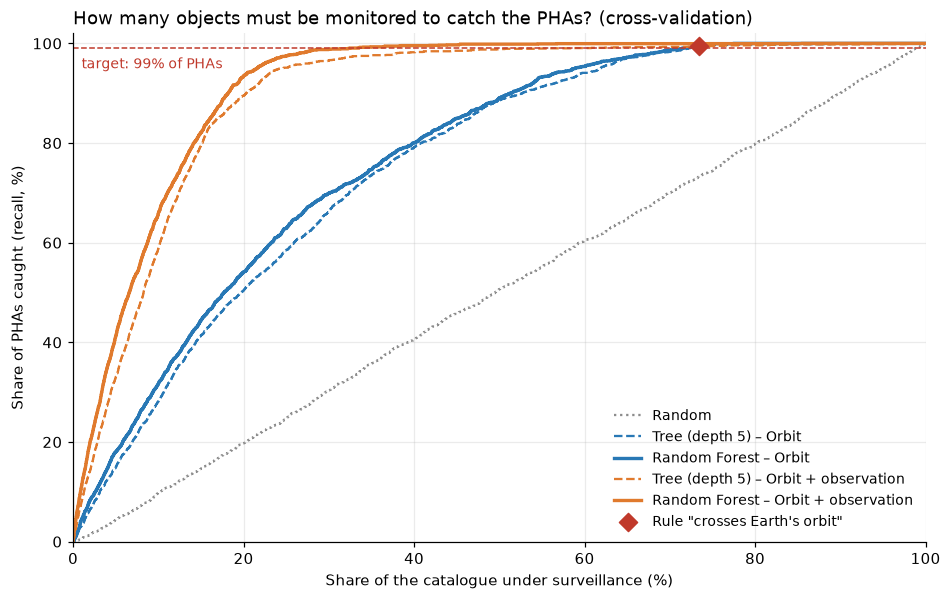

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
styles = {
    "Random": dict(color=GREY, ls=":", lw=1.5),
    "Tree (depth 5) – Orbit": dict(color=BLUE, ls="--", lw=1.5),
    "Random Forest – Orbit": dict(color=BLUE, lw=2.2),
    "Tree (depth 5) – Orbit + observation": dict(color=ORANGE, ls="--", lw=1.5),
    "Random Forest – Orbit + observation": dict(color=ORANGE, lw=2.2),
}
for name, st in styles.items():
    share, recall = workload_curve(y_train, oof[name])
    ax.plot(share * 100, recall * 100, label=name, **st)
rule = oof["Rule \"crosses Earth's orbit\""]
ax.scatter([rule.mean() * 100], [rule[y_train == 1].mean() * 100], marker="D", s=70, color=RED, zorder=5,
           label="Rule \"crosses Earth's orbit\"")
ax.axhline(RECALL_TARGET * 100, color=RED, ls="--", lw=1)
ax.text(1, RECALL_TARGET * 100 - 4, f"target: {RECALL_TARGET:.0%} of PHAs", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("Share of the catalogue under surveillance (%)")
ax.set_ylabel("Share of PHAs caught (recall, %)")
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_title("How many objects must be monitored to catch the PHAs? (cross-validation)", loc="left")
ax.legend(frameon=False, loc="lower right", fontsize=9)
save(fig, "recall_vs_workload_cv")
plt.show()

**How to read this chart:** objects are sorted from most to least suspicious, then we move right, putting more and more objects under surveillance. The curve shows the share of PHAs already caught. **The faster a curve rises, the better the model.**

- **Random** (diagonal): monitoring 50% of the catalogue only catches 50% of the PHAs.
- **The expert rule** catches almost all PHAs, but flags nearly three quarters of the catalogue: it is barely better than "monitor everything".
- **Orbit only**: a real gain over random, but reaching 99% of the PHAs still requires monitoring about 70% of the objects.
- **Orbit + observation**: the curve rises much faster. 99% of the PHAs are caught while monitoring about **a third** of the catalogue.

Reminder from step 3: part of this gain comes from size learned indirectly (large objects are tracked longer). These variables are nevertheless **available at decision time**, so this is a usable model, as long as this is stated.

**Selected model: Random Forest – Orbit + observation.** The "orbit only" model remains the proxy-free reference.

## 3. Choosing the threshold (on the training set, cross-validated)

The threshold is chosen on the **out-of-fold** probabilities of the training set, so the test set stays untouched: it is the highest threshold that catches at least 99% of the PHAs.

In [6]:
CHOSEN = "Random Forest – Orbit + observation"
REFERENCE = "Random Forest – Orbit"
thresholds = {name: threshold_for_recall(y_train, oof[name], RECALL_TARGET) for name in [CHOSEN, REFERENCE]}
for name, thr in thresholds.items():
    print(f"{name}: threshold = {thr:.3f} → {np.mean(oof[name] >= thr):.1%} of the training set flagged")

Random Forest – Orbit + observation: threshold = 0.055 → 32.3% of the training set flagged
Random Forest – Orbit: threshold = 0.062 → 71.4% of the training set flagged


## 4. Final evaluation on the test set (once)

The models are retrained on **the whole training set**, then applied to the 8,257 test objects with the threshold chosen in section 3.

In [7]:
final_models, test_proba = {}, {}
for name in [CHOSEN, REFERENCE]:
    fs = "Orbit + observation" if "observation" in name else "Orbit"
    final_models[name] = clone(best_rf[fs]).fit(train[FEATURE_SETS[fs]], y_train)
    test_proba[name] = final_models[name].predict_proba(test[FEATURE_SETS[fs]])[:, 1]

rows = []
for name, p in test_proba.items():
    for label, thr in [("threshold 0.5 (default)", 0.5), (f"threshold for {RECALL_TARGET:.0%} recall", thresholds[name])]:
        pred = p >= thr
        rows.append({
            "model": name, "threshold": label, "threshold value": thr,
            "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred),
            "missed PHAs (FN)": int(((~pred) & (y_test == 1)).sum()),
            "% of catalogue monitored": pred.mean() * 100,
            "PR-AUC": average_precision_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, p),
        })
test_table = pd.DataFrame(rows).set_index(["model", "threshold"])
test_table.to_csv(REPORT_DIR / "test_metrics.csv")
test_table.round(3)

threshold value  \
model                               threshold                                   
Random Forest – Orbit + observation threshold 0.5 (default)             0.500   
                                    threshold for 99% recall            0.055   
Random Forest – Orbit               threshold 0.5 (default)             0.500   
                                    threshold for 99% recall            0.062   

                                                              recall  \
model                               threshold                          
Random Forest – Orbit + observation threshold 0.5 (default)    0.872   
                                    threshold for 99% recall   0.990   
Random Forest – Orbit               threshold 0.5 (default)    0.654   
                                    threshold for 99% recall   0.996   

                                                              precision    F1  \
model                               threshold                                   
Random Forest – Orbit + observation threshold 0.5 (default)       0.305 0.452   
                                    threshold for 99% recall      0.185 0.312   
Random Forest – Orbit               threshold 0.5 (default)       0.140 0.230   
                                    threshold for 99% recall      0.085 0.157   

                                                              missed PHAs (FN)  \
model                               threshold                                    
Random Forest – Orbit + observation threshold 0.5 (default)                 65   
                                    threshold for 99% recall                 5   
Random Forest – Orbit               threshold 0.5 (default)                176   
                                    threshold for 99% recall                 2   

                                                              % of catalogue monitored  \
model                               threshold                                            
Random Forest – Orbit + observation threshold 0.5 (default)                     17.609   
                                    threshold for 99% recall                    32.893   
Random Forest – Orbit               threshold 0.5 (default)                     28.751   
                                    threshold for 99% recall                    72.109   

                                                              PR-AUC  ROC-AUC  
model                               threshold                                  
Random Forest – Orbit + observation threshold 0.5 (default)    0.504    0.944  
                                    threshold for 99% recall   0.504    0.944  
Random Forest – Orbit               threshold 0.5 (default)    0.165    0.784  
                                    threshold for 99% recall   0.165    0.784

**Reading:**

- **With the default threshold of 0.5**, the selected model misses about **13% of the PHAs**. This is incompatible with the PDCO policy.
- **With the threshold chosen on the training set**, it reaches **99% recall on the test set**: the target set without looking at the test is met. In exchange, about a third of the catalogue is put under surveillance.
- **The "orbit only" model** also reaches 99% recall, but by flagging more than 70% of the catalogue. It is then barely better than the expert rule.
- **Precision remains low** (about 1 flagged object in 5 is a real PHA). This is the accepted price of "zero false negatives": monitoring a harmless object costs telescope time, missing a PHA can cost much more.

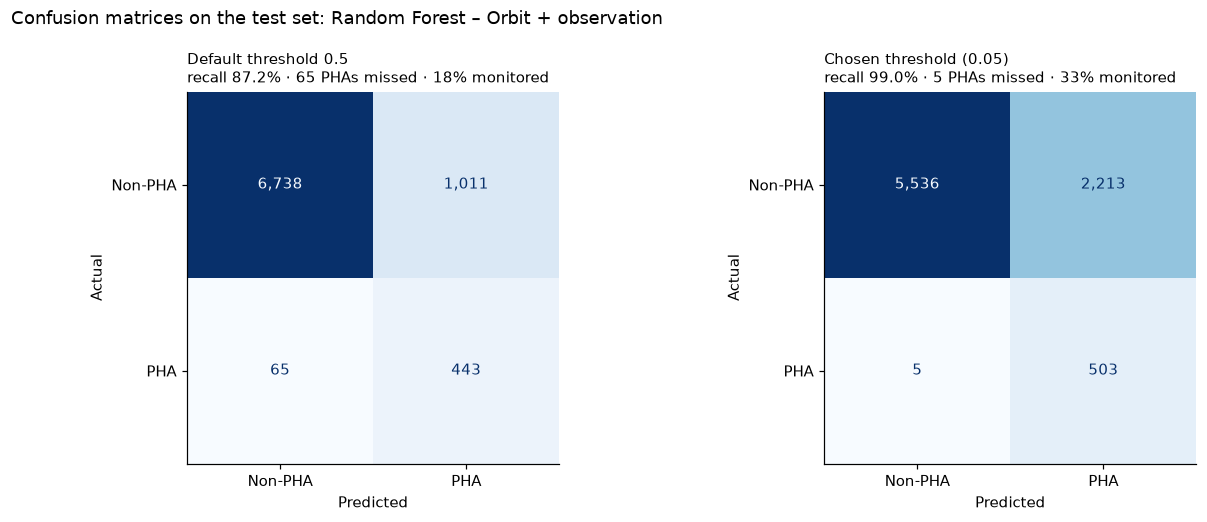

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
p = test_proba[CHOSEN]
for ax, (label, thr) in zip(axes, [("Default threshold 0.5", 0.5), (f"Chosen threshold ({thresholds[CHOSEN]:.2f})", thresholds[CHOSEN])]):
    cm = confusion_matrix(y_test, p >= thr)
    ConfusionMatrixDisplay(cm, display_labels=["Non-PHA", "PHA"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",d")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.grid(False)
    fn, tp = cm[1, 0], cm[1, 1]
    ax.set_title(f"{label}\nrecall {tp / (tp + fn):.1%} · {fn} PHAs missed · {(p >= thr).mean():.0%} monitored", loc="left", fontsize=10)
fig.suptitle(f"Confusion matrices on the test set: {CHOSEN}", x=0.01, ha="left")
fig.tight_layout()
save(fig, "confusion_matrices_test")
plt.show()

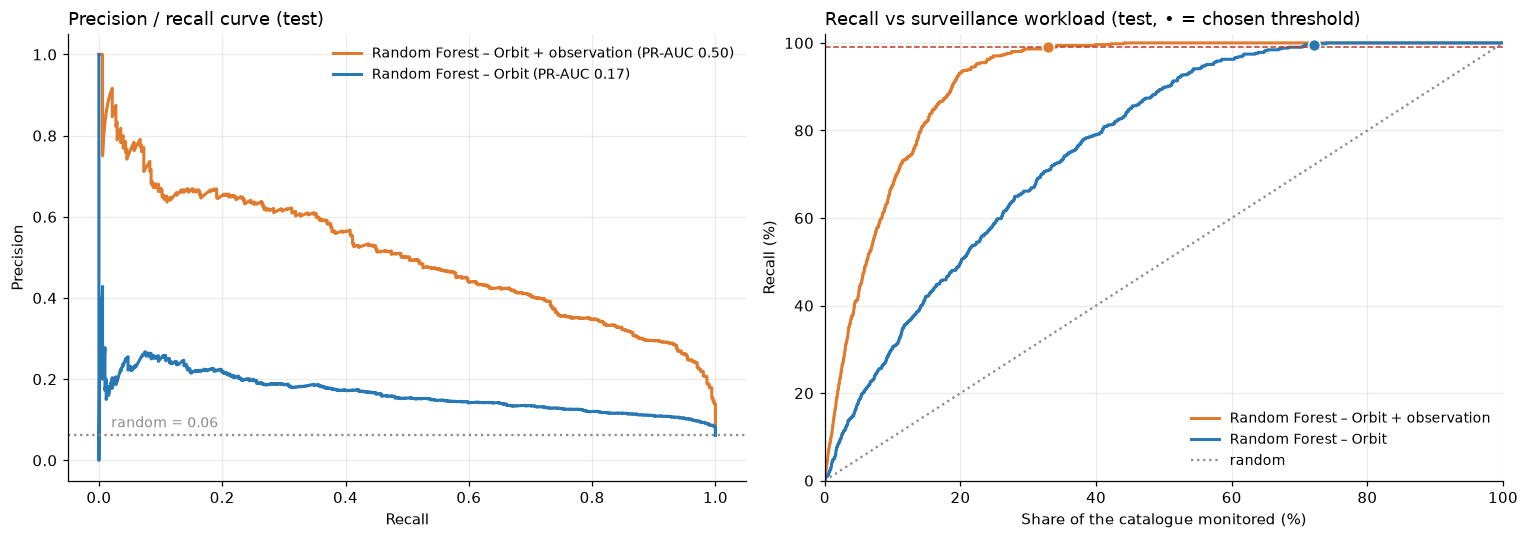

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for name, color in [(CHOSEN, ORANGE), (REFERENCE, BLUE)]:
    prec, rec, _ = precision_recall_curve(y_test, test_proba[name])
    ax.plot(rec, prec, color=color, lw=2, label=f"{name} (PR-AUC {average_precision_score(y_test, test_proba[name]):.2f})")
ax.axhline(y_test.mean(), color=GREY, ls=":", lw=1.5)
ax.text(0.02, y_test.mean() + 0.02, f"random = {y_test.mean():.2f}", color=GREY, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision / recall curve (test)", loc="left")
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
for name, color in [(CHOSEN, ORANGE), (REFERENCE, BLUE)]:
    share, recall = workload_curve(y_test, test_proba[name])
    ax.plot(share * 100, recall * 100, color=color, lw=2, label=name)
    thr = thresholds[name]
    ax.scatter([np.mean(test_proba[name] >= thr) * 100], [recall_score(y_test, test_proba[name] >= thr) * 100],
               color=color, s=60, zorder=5, edgecolor="white")
ax.plot([0, 100], [0, 100], color=GREY, ls=":", lw=1.5, label="random")
ax.axhline(RECALL_TARGET * 100, color=RED, ls="--", lw=1)
ax.set_xlabel("Share of the catalogue monitored (%)"); ax.set_ylabel("Recall (%)")
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_title("Recall vs surveillance workload (test, • = chosen threshold)", loc="left")
ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout()
save(fig, "test_curves")
plt.show()

## 5. Which PHAs are missed?

For the PDCO, missing a PHA does not always have the same severity. We look at the size (H) and the minimum distance to Earth's orbit (MOID) of the PHAs the model did not flag. These columns are **not** used by the model; they only serve to analyze its errors.

In [10]:
pred = test_proba[CHOSEN] >= thresholds[CHOSEN]
pha_test = test[y_test == 1].assign(flagged=pred[y_test == 1], proba=test_proba[CHOSEN][y_test == 1])
missed = pha_test[~pha_test["flagged"]]
missed[["pdes", "H", "moid_au", "a", "e", "i", "data_arc_years", "proba"]].sort_values("H").to_csv(
    REPORT_DIR / "missed_pha_test.csv", index=False)

compare = pd.DataFrame({
    "flagged PHAs": pha_test[pha_test["flagged"]][["H", "moid_au", "data_arc_years"]].median(),
    "missed PHAs": missed[["H", "moid_au", "data_arc_years"]].median(),
}).rename(index={"H": "median H", "moid_au": "median MOID (AU)", "data_arc_years": "median observation arc (years)"})
print(f"PHAs missed on the test set: {len(missed)} out of {len(pha_test)}")
display(missed[["pdes", "H", "moid_au", "data_arc_years", "proba"]].sort_values("data_arc_years"))
compare

PHAs missed on the test set: 5 out of 508


,pdes,H,moid_au,data_arc_years,proba
1650,2017 AG21,20.930,0.036,0.000,0.014
59,2025 SQ55,21.740,0.035,0.010,0.018
7500,2021 UV7,21.350,0.044,0.040,0.046
7727,2024 WC1,21.370,0.030,0.080,0.047
6914,756998,19.500,0.043,11.630,0.023


,flagged PHAs,missed PHAs
median H,20.530,21.350
median MOID (AU),0.022,0.036
median observation arc (years),10.760,0.040


**Reading:** the missed PHAs are almost all **very recently discovered** objects, observed for only a few days or weeks. The model relies heavily on the observation arc: an object tracked for a long time is often large, hence more often a PHA. A newly discovered object does not have that history yet, and the model underestimates it.

**Recommendation for the PDCO:** recently discovered objects need follow-up observations anyway to pin down their orbit. They must be **monitored systematically, regardless of their score**. The model is used to triage the rest of the catalogue.

## 6. What the model learned

**Permutation importance** on the test set: we shuffle one variable and measure the drop in PR-AUC.

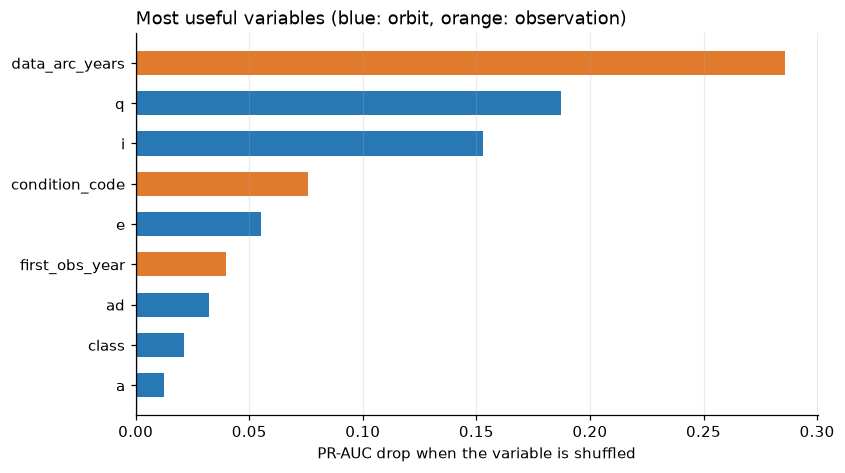

In [11]:
cols = FEATURE_SETS["Orbit + observation"]
perm = permutation_importance(final_models[CHOSEN], test[cols], y_test, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=cols).sort_values()
importance.rename("PR-AUC drop").to_csv(REPORT_DIR / "permutation_importance.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [ORANGE if c in cfg["features_orbit_obs"]["numeric"] and c not in cfg["features_orbit"]["numeric"] else BLUE
          for c in importance.index]
ax.barh(importance.index, importance.values, color=colors, height=0.6)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("PR-AUC drop when the variable is shuffled")
ax.set_title("Most useful variables (blue: orbit, orange: observation)", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "permutation_importance")
plt.show()

For the presentation, a shallow tree trained on the raw variables gives **readable rules**. It is less accurate than the forest, but shows the logic learned.

Test PR-AUC of the explanatory tree: 0.29


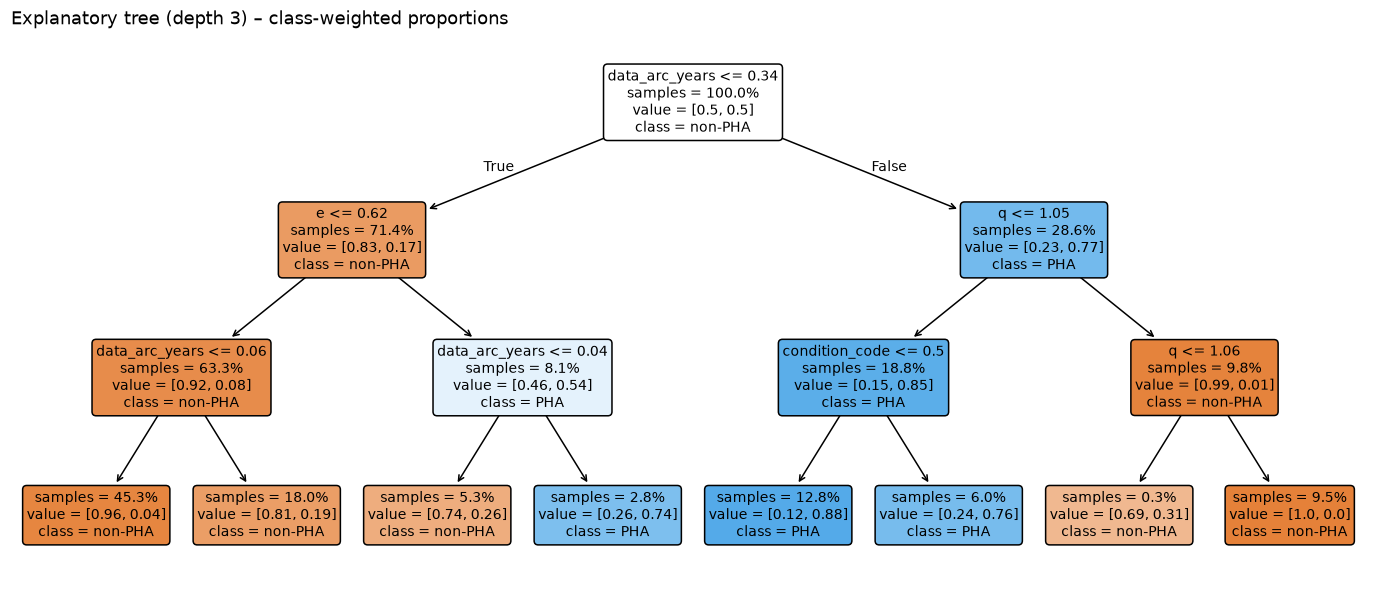

In [12]:
raw_cols = cfg["features_orbit_obs"]["numeric"]
medians = train[raw_cols].median()
explainer = DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, class_weight="balanced", random_state=RANDOM_STATE)
explainer.fit(train[raw_cols].fillna(medians), y_train)
print(f"Test PR-AUC of the explanatory tree: "
      f"{average_precision_score(y_test, explainer.predict_proba(test[raw_cols].fillna(medians))[:, 1]):.2f}")

fig, ax = plt.subplots(figsize=(16, 6.5))
plot_tree(explainer, feature_names=raw_cols, class_names=["non-PHA", "PHA"], filled=True, rounded=True,
          impurity=False, proportion=True, precision=2, fontsize=9, ax=ax)
ax.set_title("Explanatory tree (depth 3) – class-weighted proportions", loc="left")
save(fig, "explainer_tree")
plt.show()

**Reading the tree** (proportions are rebalanced between PHAs and non-PHAs):

- **First question: has the object been observed for more than about 4 months** (`data_arc_years` > 0.34)? Objects observed for a short time are mostly small, so rarely PHAs.
- **For objects tracked for a long time, the next question is about the perihelion**: if the object comes closer than 1.05 AU to the Sun (`q ≤ 1.05`), its orbit can cross Earth's, and it is classified as a PHA in a large majority of cases.
- **For recent objects**, a very elongated orbit (`e > 0.62`) increases the risk.

We find the two ingredients of the official PHA definition, seen indirectly: **size** through the observation arc, and **proximity** through the perihelion.

## 7. Scores for the whole catalogue (for step 7)

Each object gets a probability of being a PHA. To avoid overly optimistic scores, **training** objects get their **out-of-fold** probability (computed by a model that did not see them), and **test** objects get the final model's probability.

In [13]:
scores = pd.concat([
    pd.DataFrame({"pdes": train["pdes"], "split": "train",
                  "pha_proba": oof[CHOSEN], "pha_proba_orbit": oof[REFERENCE]}),
    pd.DataFrame({"pdes": test["pdes"], "split": "test",
                  "pha_proba": test_proba[CHOSEN], "pha_proba_orbit": test_proba[REFERENCE]}),
], ignore_index=True)
scores["flagged"] = scores["pha_proba"] >= thresholds[CHOSEN]
scores.to_csv(PROCESSED_DIR / "catalogue_scores.csv", index=False)
joblib.dump(final_models[CHOSEN], PROCESSED_DIR / "rf_orbit_observation.joblib")
joblib.dump(final_models[REFERENCE], PROCESSED_DIR / "rf_orbit.joblib")
(REPORT_DIR / "thresholds.json").write_text(json.dumps(
    {"recall_target": RECALL_TARGET, "thresholds": thresholds, "chosen_model": CHOSEN}, indent=2),
    encoding="utf-8")
print(f"{fmt(len(scores))} objects scored, {scores['flagged'].mean():.1%} flagged for surveillance")

41,281 objects scored, 32.4% flagged for surveillance


## Summary

| Question | Answer |
|---|---|
| Can a PHA be spotted without H or MOID? | **Partly.** The orbit alone gives a real but weak signal. With the observation variables, the model becomes useful. |
| Why not the 0.5 threshold? | It misses a large share of the PHAs. The "zero false negative" policy requires a low threshold, chosen to reach 99% recall. |
| The price of that recall | About a third of the catalogue to monitor, vs nearly three quarters with the expert rule and almost everything at random. |
| Limitation to report | The observation variables bring most of the gain, partly because they reflect size (detection bias). |
| For step 7 | The `pha_proba` probability will be combined with the pessimistic diameter from step 4 to rank objects by priority. |